# 02 — Exploratory Data Analysis

In [1]:
import sys
sys.path.append("../src")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import build_features
import plotting as P

P.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.0f}" if abs(x) >= 1000 else f"{x:,.3f}")

In [2]:
df = build_features(pd.read_csv("../data/processed/player_seasons.csv"))
paid = df[df.has_salary]
mp = df[df.modeling_sample == 1]          # has salary and >= 250 minutes
print(f"{len(df):,} player-seasons | {len(paid):,} with salary | {len(mp):,} with salary and >= 250 min")

5,968 player-seasons | 5,419 with salary | 4,488 with salary and >= 250 min


## 1. Data quality

In [3]:
miss = df[["salary", "pick_overall", "prev_vorp", "height_in", "ts_pct", "pts"]].isna().mean()
miss.to_frame("missing").style.format("{:.1%}")

,missing
salary,9.2%
pick_overall,24.7%
prev_vorp,28.5%
height_in,0.0%
ts_pct,0.0%
pts,0.0%


Missing salary = two-way/10-day deals. Missing pick = undrafted (flagged). Missing `prev_*` = no previous season.

## 2. Target: salary

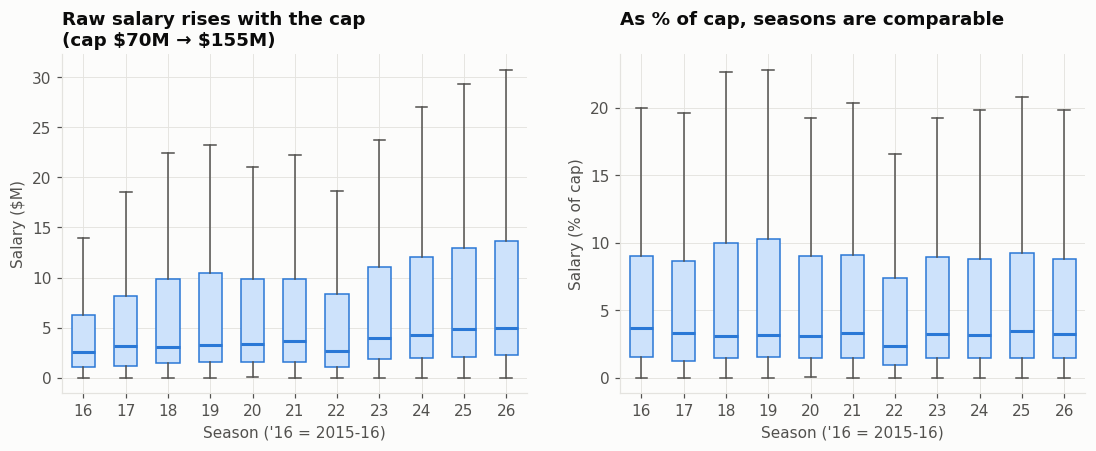

skew: 1.75 raw → -0.84 after log


In [4]:
BOX = dict(showfliers=False, patch_artist=True, boxprops=dict(facecolor="#cde2fb", edgecolor=P.BLUE),
           medianprops=dict(color=P.BLUE, linewidth=2), whiskerprops=dict(color=P.TEXT_2), capprops=dict(color=P.TEXT_2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
seasons = sorted(paid.season.unique())
cap = paid.groupby("season").salary_cap.first() / 1e6
for ax, col, scale, title, ylab in [
        (axes[0], "salary", 1e-6, f"Raw salary rises with the cap\n(cap \\${cap.iloc[0]:.0f}M → \\${cap.iloc[-1]:.0f}M)", "Salary ($M)"),
        (axes[1], "salary_pct_cap", 100, "As % of cap, seasons are comparable\n", "Salary (% of cap)")]:
    ax.boxplot([paid.loc[paid.season == s, col] * scale for s in seasons],
               labels=[str(s)[2:] for s in seasons], widths=0.55, **BOX)
    ax.set_title(title); ax.set_ylabel(ylab); ax.set_xlabel("Season ('16 = 2015-16)")
P.save(fig, "eda_salary_by_season")
plt.show()
print(f"skew: {paid.salary_pct_cap.skew():.2f} raw → {np.log(paid.salary_pct_cap).skew():.2f} after log")

**→ Target = log(salary ÷ cap).**

## 3. Pay vs. performance

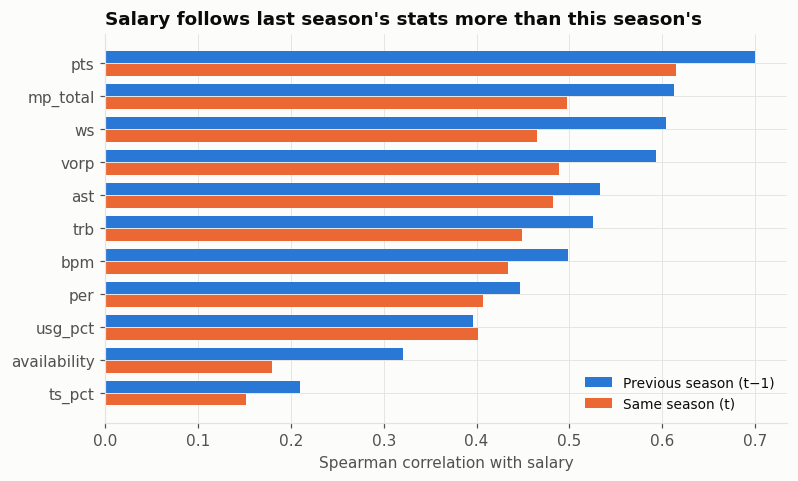

In [5]:
vets = mp[mp.has_prev_season == 1]
metrics = ["pts", "mp_total", "ws", "vorp", "ast", "trb", "bpm", "per", "usg_pct", "availability", "ts_pct"]
corr = pd.DataFrame({
    "Previous season (t−1)": [vets[f"prev_{m}"].corr(vets.salary_pct_cap, method="spearman") for m in metrics],
    "Same season (t)": [vets[m].corr(vets.salary_pct_cap, method="spearman") for m in metrics],
}, index=metrics)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(corr))
ax.barh(y + 0.19, corr.iloc[:, 0], height=0.36, color=P.BLUE, label=corr.columns[0])
ax.barh(y - 0.19, corr.iloc[:, 1], height=0.36, color=P.ORANGE, label=corr.columns[1])
ax.set_yticks(y, corr.index)
ax.set_xlabel("Spearman correlation with salary")
ax.set_title("Salary follows last season's stats more than this season's")
ax.legend(loc="lower right")
P.save(fig, "eda_corr_current_vs_prev")
plt.show()

**→ Use previous-season features.** True for 10 of 11 stats (usage rate ties).

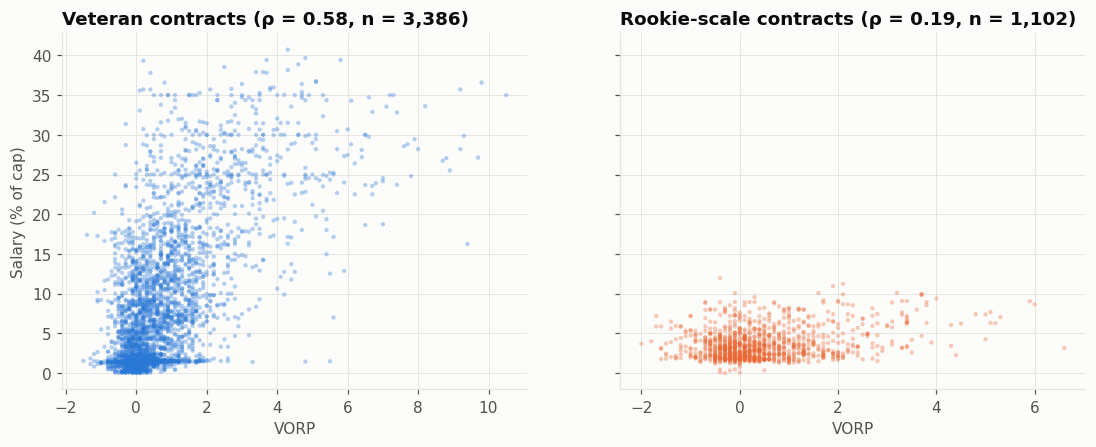

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (flag, label, color) in zip(axes, [(0, "Veteran contracts", P.BLUE), (1, "Rookie-scale contracts", P.ORANGE)]):
    sub = mp[mp.rookie_scale == flag]
    rho = sub.vorp.corr(sub.salary_pct_cap, method="spearman")
    ax.scatter(sub.vorp, sub.salary_pct_cap * 100, s=8, alpha=0.35, color=color, edgecolors="none")
    ax.set_title(f"{label} (ρ = {rho:.2f}, n = {len(sub):,})")
    ax.set_xlabel("VORP")
axes[0].set_ylabel("Salary (% of cap)")
P.save(fig, "eda_vorp_vs_salary_by_contract")
plt.show()

**→ Rookie contracts barely track production — model them separately.**

## 4. Age

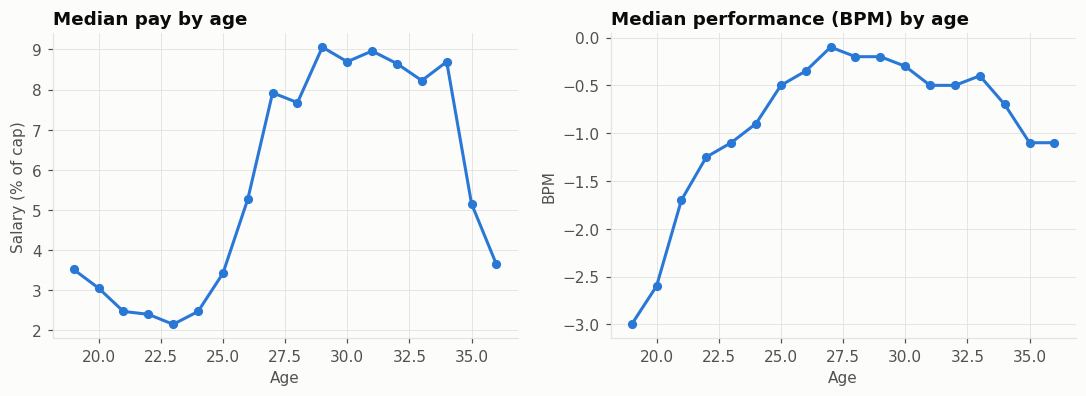

In [7]:
age = mp[mp.age.between(19, 36)].groupby("age").agg(pay=("salary_pct_cap", "median"), bpm=("bpm_raw", "median"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(age.index, age.pay * 100, color=P.BLUE, marker="o", markersize=5)
axes[0].set_title("Median pay by age"); axes[0].set_ylabel("Salary (% of cap)"); axes[0].set_xlabel("Age")
axes[1].plot(age.index, age.bpm, color=P.BLUE, marker="o", markersize=5)
axes[1].set_title("Median performance (BPM) by age"); axes[1].set_ylabel("BPM"); axes[1].set_xlabel("Age")
P.save(fig, "eda_age_curves")
plt.show()

**→ Performance peaks ~27, pay peaks 29–34: players are paid for past seasons.**

## 5. Contract stage and position

In [8]:
def stage(r):
    if r.rookie_scale: return "Rookie scale"
    if r.years_experience <= 3: return "Early career (2nd rd/undrafted)"
    return "Veteran 4–9 yrs" if r.years_experience <= 9 else "Veteran 10+ yrs"

s = mp.assign(stage=mp.apply(stage, axis=1), pos_vorp=mp.vorp.clip(lower=0)).groupby("stage")
pd.DataFrame({"n": s.size(), "median % of cap": s.salary_pct_cap.median() * 100,
              "cap % per VORP": s.salary_pct_cap.sum() / s.pos_vorp.sum() * 100}).round(1)

,n,median % of cap,cap % per VORP
stage,,,
Early career (2nd rd/undrafted),956,1.400,6.400
Rookie scale,1102,3.200,5.700
Veteran 10+ yrs,673,8.900,12.000
Veteran 4–9 yrs,1757,9.800,10.200


**→ Rookie-scale production costs about half as much per VORP as veterans.**

In [9]:
mp.groupby("pos_group").salary_pct_cap.median().mul(100).round(1).loc[["Guard", "Forward", "Center"]].to_frame("median % of cap")

,median % of cap
pos_group,
Guard,4.000
Forward,4.300
Center,4.700


**→ Position barely matters on its own — use as a control.**

## 6. Team payroll vs. wins

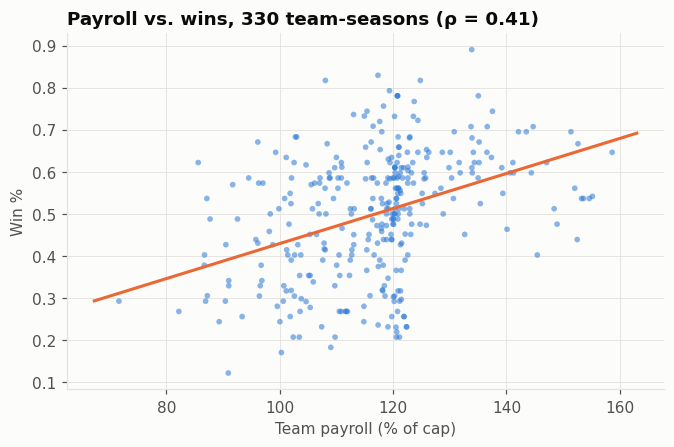

In [10]:
sal_raw = pd.read_csv("../data/raw/salaries.csv")
payroll = (sal_raw.groupby(["season", "team"]).salary.sum().reset_index()
           .merge(pd.read_csv("../data/raw/salary_cap.csv")[["season", "salary_cap"]], on="season")
           .merge(pd.read_csv("../data/raw/teams.csv"), on=["season", "team"]))
payroll["payroll_pct"] = payroll.salary / payroll.salary_cap * 100
payroll["win_pct"] = payroll.wins / (payroll.wins + payroll.losses)
rho = payroll.payroll_pct.corr(payroll.win_pct, method="spearman")
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(payroll.payroll_pct, payroll.win_pct, s=14, alpha=0.55, color=P.BLUE, edgecolors="none")
b = np.polyfit(payroll.payroll_pct, payroll.win_pct, 1)
xs = np.linspace(*ax.get_xlim(), 50); ax.plot(xs, np.polyval(b, xs), color=P.ORANGE)
ax.set_xlabel("Team payroll (% of cap)"); ax.set_ylabel("Win %")
ax.set_title(f"Payroll vs. wins, 330 team-seasons (ρ = {rho:.2f})")
P.save(fig, "eda_payroll_vs_wins")
plt.show()

**→ Money buys wins only loosely — room for *efficient* spending to matter.** (Traded players count on both teams here; fixed in the final analysis.)

## 7. Biggest pay vs. production gaps

In [11]:
r = mp.assign(pay_rank=mp.groupby("season").salary_pct_cap.rank(pct=True),
              prod_rank=mp.groupby("season").vorp.rank(pct=True))
r["gap"] = r.prod_rank - r.pay_rank
cols = ["season", "player", "salary_pct_cap", "vorp", "gap"]
fmt = {"salary_pct_cap": "{:.1%}", "vorp": "{:.1f}", "gap": "{:+.2f}"}
display(r.nlargest(5, "gap")[cols].style.format(fmt).hide(axis="index").set_caption("Underpaid"))
display(r.nsmallest(5, "gap")[cols].style.format(fmt).hide(axis="index").set_caption("Overpaid"))

season,player,salary_pct_cap,vorp,gap
2016,Hassan Whiteside,1.4%,3.3,+0.82
2018,Nikola Jokić,1.5%,5.5,+0.78
2017,Nikola Jokić,1.4%,4.8,+0.77
2019,Pascal Siakam,1.5%,2.8,+0.76
2019,Monte Morris,1.3%,1.7,+0.75


season,player,salary_pct_cap,vorp,gap
2019,Andrew Wiggins,25.0%,-0.6,-0.91
2016,Roy Hibbert,22.1%,-0.6,-0.89
2024,Jordan Poole,20.2%,-1.2,-0.88
2020,Blake Griffin,31.4%,-0.3,-0.87
2026,Khris Middleton,21.5%,-0.9,-0.86


Outliers are real cases (Jokić on a 2nd-round deal; Wiggins, Griffin, Poole on big deals with negative VORP), not data errors.